# 4x4 size scan: spin basis vs plaquette eigenbasis (+ GCNN)

**Question.** At matched parameter count, how accurate is each wavefunction on
4x4 at J2 = 0, especially below the Hilbert-space dimension (Sz = 0 sector:
12,870 states)?

**Runs** (all 4x4, J2 = 0, exact sampler, 8192 samples per step, 2 layers,
5000 steps; full settings in the tables below, read from the runs themselves):

| family | sweeps | sizes |
|---|---|---|
| spin-basis ViT | adaptive alpha (`d773272`), fixed alpha 2 (`def726f`) | d_model 6 / 12 / 24 / 48 |
| eigenbasis ViT | adaptive alpha (`d773272`), fixed alpha 2 (`def726f`) | d_model 6 / 12 / 24 / 48 |
| eigenbasis ViT, 6x6 settings | fixed alpha 1.25 (`beb1714`) | d_model 72 |
| spin-basis GCNN | fixed alpha 2, Marshall frame, real weights (`e8380f1`, Explorer) | features 2 / 4 / 8 / 14 |

Runs are grouped by **parameter count** (about 1k, 4k, 15k, 50k, 117k), since
the GCNN's sizes are not d_model values.

Exact reference: E0/site = -0.701780 (each driver computes it by ED).

**Refresh** (re-run all cells afterwards; runs in progress are labelled as such):

    rsync -av aicr:~/master/heisenberg_2d/data/ ~/Documents/master/heisenberg_2d/data/

**Reading relErr.** One step's energy (8192 samples) is noisy and its minimum
over a run is biased low, so every relErr here is from the energy **averaged
over a window of steps**.

In [1]:
import json, re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

def _find(name):
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / name).is_dir():
            return p / name
    raise FileNotFoundError(f"no '{name}' folder above {Path.cwd()}")

DATA = _find("data")
SWEEPS = [   # (family, sweep folder); alpha mode and sign rule are read from each run's config
    ("spin",  DATA / "spinbasis"  / "2026-10-08_19-28-13Gd773272P1519525"),   # ViT, adaptive alpha
    ("spin",  DATA / "spinbasis"  / "2026-10-08_21-44-09Gdef726fP208982"),    # ViT, fixed alpha 2
    ("eigen", DATA / "eigenbasis" / "2026-10-08_19-28-24Gd773272P1523473"),   # ViT, adaptive alpha
    ("eigen", DATA / "eigenbasis" / "2026-10-08_21-44-16Gdef726fP216176"),    # ViT, fixed alpha 2
    ("eigen", DATA / "eigenbasis" / "2026-10-09_00-45-16Gbeb1714P4147729"),   # ViT d72, alpha 1.25 (6x6 settings)
    ("gcnn",  DATA / "spinbasis"  / "2026-10-09_00-39-16Ge8380f1P1621831"),   # GCNN, Marshall frame
]
N_SITES = 16
SMOOTH = 50                                   # steps per window for the relErr curves
SIZE_CLASSES = [1e3, 4e3, 1.5e4, 5e4, 1.17e5]  # parameter-count groups (log-nearest)
CLASS_LABEL = ["~1k", "~4k", "~15k", "~50k", "~117k"]

# Colours: categorical palette slots 1-3 (spin blue and eigen orange as in
# EIGENBASIS_VS_SPINBASIS.ipynb; GCNN aqua). Line style = alpha setting.
C = {"spin": "#2a78d6", "eigen": "#eb6834", "gcnn": "#1baf7a"}
FAM = {"spin": "spin-basis ViT", "eigen": "eigenbasis ViT", "gcnn": "spin-basis GCNN (Marshall frame)"}
LS = {"fixed 2": "-", "adaptive": (0, (4, 2)), "fixed 1.25": (0, (1, 1.5))}
MARK = {"fixed 2": "o", "adaptive": "^", "fixed 1.25": "s"}
INK, INK2, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titlecolor": INK,
    "legend.frameon": False, "figure.dpi": 110,
})
print("data:", DATA)
for f, s in SWEEPS:
    print(f"{f:6s}", s.name, "" if s.is_dir() else "  <-- MISSING")

data: /Users/ashilcusky/Documents/master/heisenberg_2d/data
spin   2026-10-08_19-28-13Gd773272P1519525 
spin   2026-10-08_21-44-09Gdef726fP208982 
eigen  2026-10-08_19-28-24Gd773272P1523473 
eigen  2026-10-08_21-44-16Gdef726fP216176 
eigen  2026-10-09_00-45-16Gbeb1714P4147729 
gcnn   2026-10-09_00-39-16Ge8380f1P1621831 


In [2]:
def load_energy(run):
    # Merge every *.log (one per window in the spin basis); the last write of a step wins.
    e = {}
    for f in sorted(run.glob("*.log")):
        en = json.load(open(f))["Energy"]
        ms = en["Mean"]
        ms = ms["real"] if isinstance(ms, dict) else ms
        for i, m in zip(en["iters"], ms):
            e[int(i)] = np.nan if m is None else float(m)
    s = np.array(sorted(e), dtype=int)
    return s, np.array([e[k] for k in s]) / N_SITES

def load_e0(run):
    # Full precision from the summary when the run finished; the log text has only 8 decimals.
    for f in [run / "run.summary.json", *sorted(run.glob("*.summary.json"))]:
        if f.exists() and json.load(open(f)).get("E0") is not None:
            return json.load(open(f))["E0"] / N_SITES
    m = re.search(r"ED ground-state energy\s+E0 = (\S+)", (run / "stdout.txt").read_text(errors="replace"))
    return float(m.group(1)) / N_SITES if m else np.nan

def load_run(family, run):
    cfg = json.load(open(run / "config.json"))
    man = json.load(open(run / "manifest.json"))
    mo, dist = cfg["model"], cfg["distribution"]
    summ = json.load(open(run / "run.summary.json")) if (run / "run.summary.json").exists() else {}
    n_params = summ.get("n_params")
    if n_params is None:
        m = re.search(r"n_params\s*=\s*(\d+)", (run / "stdout.txt").read_text(errors="replace"))
        n_params = int(m.group(1)) if m else None
    if family == "gcnn":
        size = f"features {mo['gcnn']['features']}"
    elif family == "spin":
        size = f"d_model {mo['vit']['d_model']}"
    else:
        size = f"d_model {mo['ratio'] * mo['heads']}"
    setting = "adaptive" if dist["auto_alpha"] else f"fixed {dist['alpha']:g}"
    s, E = load_energy(run)
    diag = [json.loads(l) for l in open(run / "run.diag.jsonl")] if (run / "run.diag.jsonl").exists() else []
    finite = np.isfinite(E)
    last = int(s[finite][-1]) if finite.any() else 0
    status = man.get("status") or "running"
    cls = int(np.argmin([abs(np.log(n_params / c)) for c in SIZE_CLASSES])) if n_params else None
    return dict(family=family, setting=setting, cfg=cfg, sweep=run.parent.name, run=run.name,
                size=size, n_params=n_params, cls=cls, status=status,
                diverged=bool((~finite).any()) and status != "completed",
                last=last, target=mo["iter"], steps=s, E=E, e0=load_e0(run), diag=diag)

RUNS, MISSING = [], []
for fam, sweep in SWEEPS:
    for run in sorted(sweep.glob("run_*")):
        if (run / "manifest.json").exists() and (run / "config.json").exists():
            RUNS.append(load_run(fam, run))
        else:
            MISSING.append((fam, f"{sweep.name}/{run.name}"))

_e0 = [r["e0"] for r in RUNS if np.isfinite(r["e0"])]
E0 = max(_e0, key=lambda x: len(repr(x)))   # the most precise copy (all runs: same ED)
CLASSES = sorted({r["cls"] for r in RUNS})
VARIANTS = sorted({(r["family"], r["setting"]) for r in RUNS},
                  key=lambda v: (list(C).index(v[0]), list(LS).index(v[1])))
label = lambda f, st: f"{FAM[f]}, alpha {st}"
print(f"loaded {len(RUNS)} runs; E0/site from ED = {E0:.6f}")
if MISSING:
    print("not started yet:", ", ".join(f"{f} {n}" for f, n in MISSING))

loaded 21 runs; E0/site from ED = -0.701780


In [3]:
def summary(r):
    c = r["cfg"]; s, o, dist, m = c["system"], c["optimizer"], c["distribution"], c["model"]
    n_samp = c["sampler"].get("N_SAMPLES") or 2048 * c["sampler"]["MONTECARLO"]
    if r["family"] == "gcnn":
        g = m["gcnn"]
        net = f"GCNN, {g['symmetries']} + spin flip (parity {g['parity']}), {g['param_dtype']} weights"
        layers, width = g["layers"], f"features {g['features']}"
    elif r["family"] == "spin":
        v = m["vit"]; layers = v["num_layers"]
        net = f"ViT, factored attention, patch {v['patch_size']}x{v['patch_size']}"
        width = f"d_model {v['d_model']}, {v['n_heads']} heads"
    else:
        layers = m["layers"]
        net = f"ViT, {m['attention_mode']} attention, 2x2 plaquette tokens, embedding {m['embedding']}"
        width = f"d_model {m['ratio'] * m['heads']}, {m['heads']} heads"
    return {
        "lattice": f"{s['L']}x{s['L']} periodic", "J1, J2": f"{s['J1']}, {s['J2']}",
        "sign rule": s["sign_rule"], "sampler": c["sampler"]["SAMPLER"], "samples / step": f"{n_samp:,}",
        "network": net, "layers": layers, "width": width, "params": f"{r['n_params']:,}",
        "alpha": f"{dist['alpha']:g} ({'adaptive start' if dist['auto_alpha'] else 'fixed'})",
        "learning rate": f"{o['initial_learning_rate']:g} -> {o['final_learning_rate']:g} over {o['lr_transition_steps']} steps",
        "diag shift": f"{o['initial_diagonal_shift']:g} -> {o['final_diagonal_shift']:g} over {o['ds_transition_steps']} steps",
        "NTK solver": dist["use_ntk"], "steps": m["iter"], "seed": c["sampler"]["seed"],
    }

S = [summary(r) for r in RUNS]
keys = list(S[0])
shared = [k for k in keys if len({str(x[k]) for x in S}) == 1]
per_fam = [k for k in keys if k not in shared and all(
    len({str(x[k]) for x, r in zip(S, RUNS) if r["family"] == f}) == 1 for f in C if any(r["family"] == f for r in RUNS))]
varies = [k for k in keys if k not in shared and k not in per_fam]

t = ["| setting | value |", "|---|---|"] + [f"| {k} | {S[0][k]} |" for k in shared]
display(Markdown("**Identical in every run**\n\n" + "\n".join(t)))
fams = [f for f in C if any(r["family"] == f for r in RUNS)]
t = ["| setting | " + " | ".join(FAM[f] for f in fams) + " |", "|---|" + "---|" * len(fams)]
for k in per_fam:
    t.append(f"| {k} | " + " | ".join(next(str(x[k]) for x, r in zip(S, RUNS) if r["family"] == f) for f in fams) + " |")
display(Markdown("**Fixed within each family, different between families**\n\n" + "\n".join(t)))
order = sorted(range(len(RUNS)), key=lambda i: (list(C).index(RUNS[i]["family"]), RUNS[i]["setting"], RUNS[i]["n_params"]))
t = ["| family | sweep / run | " + " | ".join(varies) + " |", "|---|---|" + "---|" * len(varies)]
for i in order:
    r = RUNS[i]
    t.append(f"| {FAM[r['family']]} | `{r['sweep'][:19]}` {r['run']} | " + " | ".join(str(S[i][k]) for k in varies) + " |")
display(Markdown("**What varies between runs**\n\n" + "\n".join(t)))

**Identical in every run**

| setting | value |
|---|---|
| lattice | 4x4 periodic |
| J1, J2 | 1.0, 0.0 |
| sampler | exact |
| samples / step | 8,192 |
| layers | 2 |
| learning rate | 0.05 -> 0.02 over 400 steps |
| diag shift | 0.001 -> 0.0001 over 400 steps |
| NTK solver | True |
| steps | 5000 |
| seed | 0 |

**Fixed within each family, different between families**

| setting | spin-basis ViT | eigenbasis ViT | spin-basis GCNN (Marshall frame) |
|---|---|---|---|
| sign rule | FF | FF | TF |
| network | ViT, factored attention, patch 2x2 | ViT, factored attention, 2x2 plaquette tokens, embedding qn | GCNN, space_group + spin flip (parity 1), float64 weights |

**What varies between runs**

| family | sweep / run | width | params | alpha |
|---|---|---|---|---|
| spin-basis ViT | `2026-10-08_19-28-13` run_0000 | d_model 6, 1 heads | 1,010 | 2 (adaptive start) |
| spin-basis ViT | `2026-10-08_19-28-13` run_0001 | d_model 12, 2 heads | 3,604 | 2 (adaptive start) |
| spin-basis ViT | `2026-10-08_19-28-13` run_0002 | d_model 24, 4 heads | 13,544 | 2 (adaptive start) |
| spin-basis ViT | `2026-10-08_19-28-13` run_0003 | d_model 48, 8 heads | 52,432 | 2 (adaptive start) |
| spin-basis ViT | `2026-10-08_21-44-09` run_0000 | d_model 6, 1 heads | 1,010 | 2 (fixed) |
| spin-basis ViT | `2026-10-08_21-44-09` run_0001 | d_model 12, 2 heads | 3,604 | 2 (fixed) |
| spin-basis ViT | `2026-10-08_21-44-09` run_0002 | d_model 24, 4 heads | 13,544 | 2 (fixed) |
| spin-basis ViT | `2026-10-08_21-44-09` run_0003 | d_model 48, 8 heads | 52,432 | 2 (fixed) |
| eigenbasis ViT | `2026-10-08_19-28-24` run_0000 | d_model 6, 1 heads | 1,016 | 2 (adaptive start) |
| eigenbasis ViT | `2026-10-08_19-28-24` run_0001 | d_model 12, 2 heads | 3,616 | 2 (adaptive start) |
| eigenbasis ViT | `2026-10-08_19-28-24` run_0002 | d_model 24, 4 heads | 13,568 | 2 (adaptive start) |
| eigenbasis ViT | `2026-10-08_19-28-24` run_0003 | d_model 48, 8 heads | 52,480 | 2 (adaptive start) |
| eigenbasis ViT | `2026-10-09_00-45-16` run_0000 | d_model 72, 12 heads | 116,736 | 1.25 (fixed) |
| eigenbasis ViT | `2026-10-08_21-44-16` run_0000 | d_model 6, 1 heads | 1,016 | 2 (fixed) |
| eigenbasis ViT | `2026-10-08_21-44-16` run_0001 | d_model 12, 2 heads | 3,616 | 2 (fixed) |
| eigenbasis ViT | `2026-10-08_21-44-16` run_0002 | d_model 24, 4 heads | 13,568 | 2 (fixed) |
| eigenbasis ViT | `2026-10-08_21-44-16` run_0003 | d_model 48, 8 heads | 52,480 | 2 (fixed) |
| spin-basis GCNN (Marshall frame) | `2026-10-09_00-39-16` run_0000 | features 2 | 1,062 | 2 (fixed) |
| spin-basis GCNN (Marshall frame) | `2026-10-09_00-39-16` run_0001 | features 4 | 4,172 | 2 (fixed) |
| spin-basis GCNN (Marshall frame) | `2026-10-09_00-39-16` run_0002 | features 8 | 16,536 | 2 (fixed) |
| spin-basis GCNN (Marshall frame) | `2026-10-09_00-39-16` run_0003 | features 14 | 50,442 | 2 (fixed) |

In [4]:
def window_relerr(r, a, b):
    m = (r["steps"] >= a) & (r["steps"] < b) & np.isfinite(r["E"])
    if m.sum() < 20: return np.nan
    return abs((r["E"][m].mean() - E0) / E0)

def diag_median(r, key, a, b):
    v = [x[key] for x in r["diag"] if a <= x["step"] < b and x[key] == x[key]]
    return float(np.median(v)) if v else np.nan

def state(r):
    if r["status"] == "completed": return "completed"
    if r["diverged"]: return f"**diverged** (NaN after step {r['last']})"
    return f"{r['status']} (step {r['last']} of {r['target']})"

fmt = lambda x: "–" if not np.isfinite(x) else f"{x:.1e}"
WIN = [(0, 200), (500, 1000), (1000, 2000), (2000, 3000), (4000, 5000)]
rows = ["| family | alpha | size | params | " + " | ".join(f"{a}–{b}" for a, b in WIN)
        + " | Var/site, last 500 | state |",
        "|---|---|---|---|" + "---|" * len(WIN) + "---|---|"]
for i in order:
    r = RUNS[i]; a = max(0, r["last"] - 500)
    rows.append(f"| {FAM[r['family']]} | {r['setting']} | {r['size']} | {r['n_params']:,} | "
                + " | ".join(fmt(window_relerr(r, *w)) for w in WIN)
                + f" | {fmt(diag_median(r, 'var_eloc_per_site', a, r['last'] + 1))} | {state(r)} |")
for f, n in MISSING:
    rows.append(f"| {FAM[f]} | – | – | – | " + " | ".join("–" for _ in WIN) + f" | – | not started ({n}) |")
display(Markdown("**relErr of the window-mean energy, by step window**\n\n" + "\n".join(rows)))

**relErr of the window-mean energy, by step window**

| family | alpha | size | params | 0–200 | 500–1000 | 1000–2000 | 2000–3000 | 4000–5000 | Var/site, last 500 | state |
|---|---|---|---|---|---|---|---|---|---|---|
| spin-basis ViT | adaptive | d_model 6 | 1,010 | 1.0e-01 | 9.0e-01 | – | – | – | 1.9e-01 | **diverged** (NaN after step 523) |
| spin-basis ViT | adaptive | d_model 12 | 3,604 | 5.2e-02 | 8.1e-05 | 1.7e-05 | 9.5e-06 | 7.3e-06 | 1.6e-05 | completed |
| spin-basis ViT | adaptive | d_model 24 | 13,544 | 6.8e-02 | 7.1e-06 | 1.8e-06 | 5.5e-07 | 1.8e-07 | 2.0e-07 | completed |
| spin-basis ViT | adaptive | d_model 48 | 52,432 | 9.4e-02 | 2.0e-06 | 5.9e-07 | 1.7e-07 | 3.1e-08 | 4.0e-08 | completed |
| spin-basis ViT | fixed 2 | d_model 6 | 1,010 | 4.9e-01 | 6.4e-01 | 6.4e-01 | 6.4e-01 | 6.4e-01 | 6.2e-33 | completed |
| spin-basis ViT | fixed 2 | d_model 12 | 3,604 | 5.8e-02 | 1.1e-04 | 4.8e-05 | 2.0e-05 | 1.7e-05 | 9.2e-05 | completed |
| spin-basis ViT | fixed 2 | d_model 24 | 13,544 | 9.2e-02 | 1.7e-05 | 7.8e-06 | 3.7e-06 | 1.9e-06 | 1.1e-05 | completed |
| spin-basis ViT | fixed 2 | d_model 48 | 52,432 | 6.6e-02 | 3.4e-06 | 1.1e-06 | 4.7e-07 | 3.0e-08 | 1.0e-06 | completed |
| eigenbasis ViT | adaptive | d_model 6 | 1,016 | 4.0e-01 | 4.0e-01 | 4.5e-01 | 8.0e-01 | – | 1.2e-01 | **diverged** (NaN after step 2378) |
| eigenbasis ViT | adaptive | d_model 12 | 3,616 | 1.6e-01 | 4.1e-01 | 5.5e-01 | – | – | 2.3e-01 | **diverged** (NaN after step 1399) |
| eigenbasis ViT | adaptive | d_model 24 | 13,568 | 2.0e-01 | 3.8e-01 | 4.5e-01 | 4.5e-01 | – | 3.5e-01 | **diverged** (NaN after step 3329) |
| eigenbasis ViT | adaptive | d_model 48 | 52,480 | 3.5e-01 | 4.3e-01 | 3.9e-01 | – | – | 1.5e-01 | **diverged** (NaN after step 1256) |
| eigenbasis ViT | fixed 1.25 | d_model 72 | 116,736 | 4.9e-01 | 4.0e-01 | 2.2e-01 | 5.0e-02 | 4.9e-02 | 9.6e-07 | completed |
| eigenbasis ViT | fixed 2 | d_model 6 | 1,016 | 1.8e-01 | 5.8e-02 | 2.4e-01 | 6.9e-02 | 6.9e-02 | 3.9e-08 | completed |
| eigenbasis ViT | fixed 2 | d_model 12 | 3,616 | 1.8e-01 | 7.8e-02 | 2.1e-01 | 1.2e-01 | 1.9e-01 | 2.5e-02 | completed |
| eigenbasis ViT | fixed 2 | d_model 24 | 13,568 | 9.9e-02 | 3.6e-02 | 3.3e-02 | 3.3e-02 | 3.3e-02 | 1.6e-04 | completed |
| eigenbasis ViT | fixed 2 | d_model 48 | 52,480 | 1.1e-01 | 1.5e-02 | 1.4e-02 | 1.4e-02 | 1.4e-02 | 6.3e-04 | completed |
| spin-basis GCNN (Marshall frame) | fixed 2 | features 2 | 1,062 | 2.9e-03 | 7.9e-10 | 4.6e-12 | 0.0e+00 | 7.9e-16 | 3.6e-30 | completed |
| spin-basis GCNN (Marshall frame) | fixed 2 | features 4 | 4,172 | 2.2e-03 | 7.8e-11 | 1.0e-13 | 7.9e-16 | 7.9e-16 | 3.4e-30 | completed |
| spin-basis GCNN (Marshall frame) | fixed 2 | features 8 | 16,536 | 2.4e-03 | 1.3e-09 | 4.7e-11 | 1.9e-14 | 7.9e-16 | 4.0e-30 | completed |
| spin-basis GCNN (Marshall frame) | fixed 2 | features 14 | 50,442 | 2.2e-03 | 5.1e-10 | 4.4e-12 | 4.1e-15 | 7.9e-16 | 3.6e-30 | completed |

## 1. Convergence at matched size

One panel per parameter-count group. Colour = wavefunction family, line style =
alpha (solid fixed 2, dashed adaptive, dotted fixed 1.25). Each curve is the
relErr of the energy averaged over consecutive 50-step windows; a cross marks the
last finite window of a run that diverged. The axis stops at 1e-10: the GCNN
runs go below it (see the table).

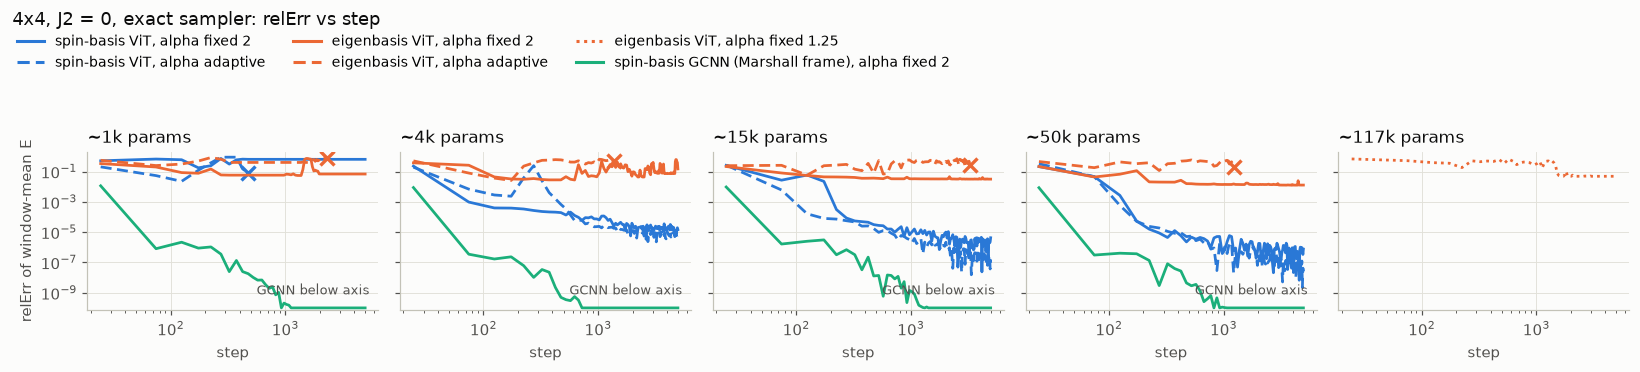

In [5]:
FLOOR = 1e-10
fig, axes = plt.subplots(1, len(CLASSES), figsize=(3.0 * len(CLASSES), 3.4), sharex=True, sharey=True)
for ax, k in zip(np.atleast_1d(axes), CLASSES):
    here = [r for r in RUNS if r["cls"] == k]
    ax.set_title(f"{CLASS_LABEL[k]} params", loc="left")
    below = False
    for r in here:
        s, E = r["steps"], r["E"]
        nwin = len(s) // SMOOTH
        if nwin == 0: continue
        sw = s[: nwin * SMOOTH].reshape(nwin, SMOOTH); Ew = E[: nwin * SMOOTH].reshape(nwin, SMOOTH)
        ok = np.isfinite(Ew).all(axis=1)
        x = sw.mean(axis=1)[ok]; y = np.abs((Ew.mean(axis=1)[ok] - E0) / E0)
        below |= bool((y < FLOOR).any())
        ax.plot(x, np.maximum(y, FLOOR), color=C[r["family"]], ls=LS[r["setting"]], lw=1.8)
        if r["diverged"] and len(x):
            ax.plot(x[-1], y[-1], marker="x", ms=9, mew=2.2, color=C[r["family"]], ls="none")
    if below:
        ax.annotate("GCNN below axis", (0.97, 0.10), xycoords="axes fraction", ha="right",
                    color=INK2, fontsize=8.5)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(FLOOR * 0.7, 2)
    ax.set_xlabel("step")
np.atleast_1d(axes)[0].set_ylabel("relErr of window-mean E")
fig.suptitle("4x4, J2 = 0, exact sampler: relErr vs step", x=0.01, ha="left", color=INK, fontsize=12)
fig.legend(handles=[plt.Line2D([], [], color=C[f], ls=LS[st], lw=2, label=label(f, st)) for f, st in VARIANTS],
           loc="upper left", ncol=3, bbox_to_anchor=(0.005, 0.95), fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.80))
plt.show()

## 2. Accuracy vs parameter count

Marker shape = alpha (circle fixed 2, triangle adaptive, square fixed 1.25).
Filled: the mean energy over the last 500 steps (or the steps so far, for a run
in progress). Hollow: runs that diverged, at their **best** 200-step window,
an optimistic number. The dashed line marks the dimension of the Sz = 0 sector.

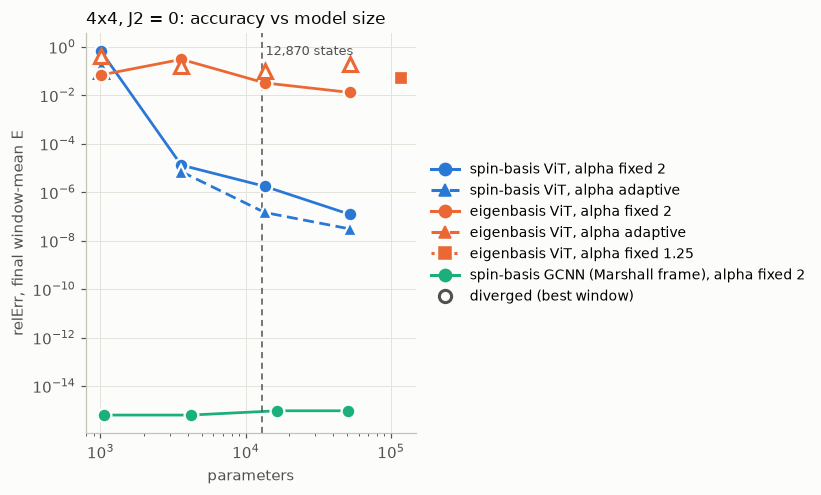

In [6]:
fig, ax = plt.subplots(figsize=(7.6, 4.6))
for f, st in VARIANTS:
    rs = sorted([r for r in RUNS if r["family"] == f and r["setting"] == st], key=lambda r: r["n_params"])
    xs, ys = [], []
    for r in rs:
        if r["diverged"]:
            best = np.nanmin([window_relerr(r, a, a + 200) for a in range(0, max(r["last"], 1), 100)] + [np.nan])
            ax.plot(r["n_params"], best, marker=MARK[st], ms=9, mfc=SURF, mec=C[f], mew=2, ls="none", zorder=3)
        else:
            y = window_relerr(r, max(0, r["last"] - 500), r["last"] + 1)
            xs.append(r["n_params"]); ys.append(y)
            ax.plot(r["n_params"], y, marker=MARK[st], ms=9, color=C[f], mec=SURF, mew=1.5, ls="none", zorder=3)
            if r["status"] != "completed":
                ax.annotate(f"step {r['last']}", (r["n_params"], y), xytext=(7, -3),
                            textcoords="offset points", color=INK2, fontsize=8.5)
    if len(xs) > 1:
        ax.plot(xs, ys, color=C[f], ls=LS[st], lw=1.8, zorder=2)
    ax.plot([], [], marker=MARK[st], ms=8, color=C[f], ls=LS[st], label=label(f, st))
ax.plot([], [], marker="o", ms=8, mfc=SURF, mec=INK2, mew=2, ls="none", label="diverged (best window)")
ax.axvline(12870, color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(12870, 0.97, " 12,870 states", transform=ax.get_xaxis_transform(), color=INK2, fontsize=8.5, va="top")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("parameters"); ax.set_ylabel("relErr, final window-mean E")
ax.set_title("4x4, J2 = 0: accuracy vs model size", loc="left")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
fig.tight_layout()
plt.show()

## 3. Sampling and stability

Alpha, the importance-weight ESS (fraction of the 8192 samples) and
Var(E_loc)/site, logged every 20 steps. Fixed-alpha runs sit at their alpha
with ESS = 1 by construction. Var/site goes to zero for **any** state on which
E_loc is constant: the exact ground state (the GCNN), an excited eigenstate, or a
wavefunction collapsed onto a few configurations. The variance axis stops at
1e-12.

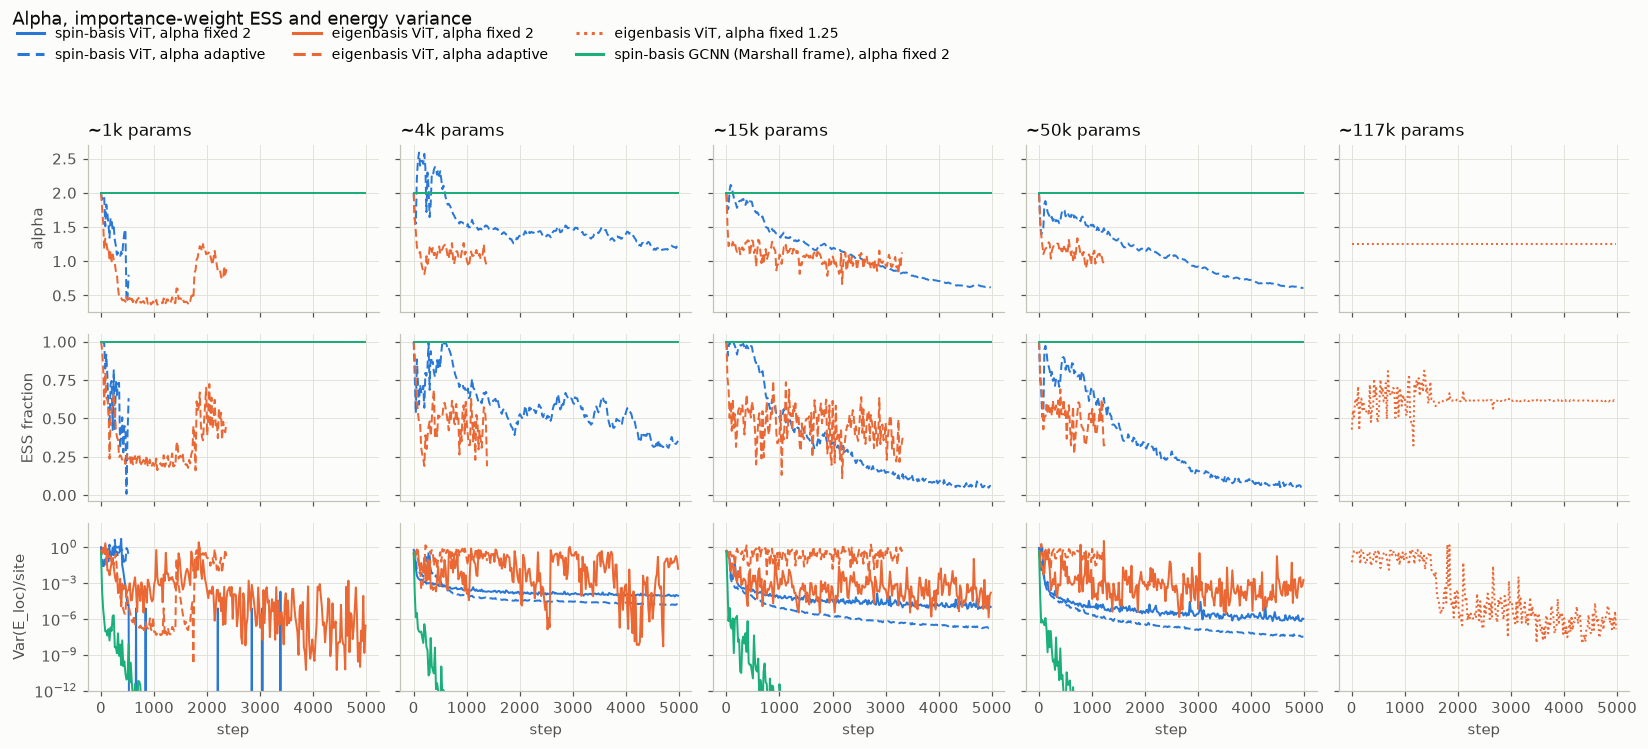

In [7]:
ROWS = [("alpha", "alpha", "linear"), ("ess_w_frac", "ESS fraction", "linear"),
        ("var_eloc_per_site", "Var(E_loc)/site", "log")]
fig, axes = plt.subplots(len(ROWS), len(CLASSES), figsize=(3.0 * len(CLASSES), 2.3 * len(ROWS)),
                         sharex=True, sharey="row", squeeze=False)
for j, k in enumerate(CLASSES):
    axes[0, j].set_title(f"{CLASS_LABEL[k]} params", loc="left")
    for r in [r for r in RUNS if r["cls"] == k]:
        st = np.array([x["step"] for x in r["diag"]])
        for i, (key, _, _) in enumerate(ROWS):
            v = np.array([x[key] for x in r["diag"]], dtype=float)
            axes[i, j].plot(st, v, color=C[r["family"]], ls=LS[r["setting"]], lw=1.3)
for i, (_, lab, sc) in enumerate(ROWS):
    axes[i, 0].set_ylabel(lab)
    for ax in axes[i]:
        ax.set_yscale(sc)
for ax in axes[2]:
    ax.set_ylim(1e-12, 1e2)
for ax in axes[-1]:
    ax.set_xlabel("step")
fig.suptitle("Alpha, importance-weight ESS and energy variance", x=0.01, ha="left", color=INK, fontsize=12)
fig.legend(handles=[plt.Line2D([], [], color=C[f], ls=LS[st], lw=2, label=label(f, st)) for f, st in VARIANTS],
           loc="upper left", ncol=3, bbox_to_anchor=(0.005, 0.975), fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.90))
plt.show()

## 4. Where the eigenbasis runs went

E/site of every eigenbasis run, every step, against the exact ground state; one
row per alpha setting. A long flat stretch with near-zero variance (§3) is a
stationary point the optimizer cannot leave.

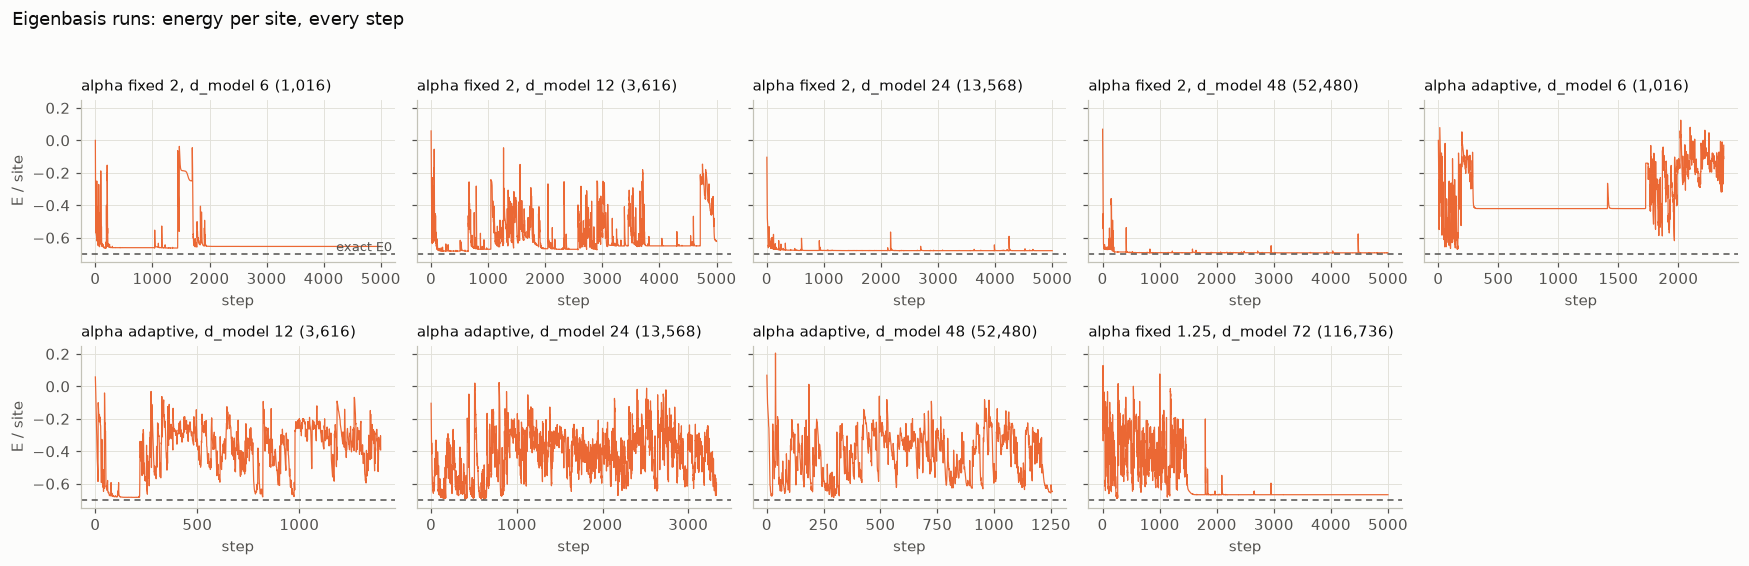

In [8]:
eig = sorted([r for r in RUNS if r["family"] == "eigen"],
             key=lambda r: (list(LS).index(r["setting"]), r["n_params"]))
if eig:
    ncol = 5
    nrow = -(-len(eig) // ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 2.6 * nrow), sharey=True, squeeze=False)
    for ax, r in zip(axes.flat, eig):
        ax.plot(r["steps"], r["E"], color=C["eigen"], lw=0.8)
        ax.axhline(E0, color=INK2, lw=1, ls=(0, (4, 3)))
        ax.set_title(f"alpha {r['setting']}, {r['size']} ({r['n_params']:,})", loc="left", fontsize=9.5)
        ax.set_xlabel("step")
    for ax in list(axes.flat)[len(eig):]:
        ax.set_visible(False)
    for ax in axes[:, 0]: ax.set_ylabel("E / site")
    axes[0, 0].text(0.99, E0, "exact E0", transform=axes[0, 0].get_yaxis_transform(), ha="right",
                    va="bottom", color=INK2, fontsize=8.5)
    fig.suptitle("Eigenbasis runs: energy per site, every step", x=0.01, ha="left", color=INK, fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

## 5. Reading (data fetched 2026-10-09)

- **The GCNN is exact on 4x4, at every size.** relErr ~1e-15 (machine
  precision) and zero energy variance by step ~2000, from 1,062 parameters up. But this is memorization,
  not compression: under the full space group and spin flip the Sz = 0
  configurations fall into only **107 symmetry classes**, so a fully symmetric
  network needs 107 numbers, and in the Marshall frame at J2 = 0 they are all
  positive. 4x4 cannot tell how well a GCNN compresses; that needs 6x6 or larger.
- **Fixed alpha removes the ViT NaNs** (0 of 8 diverged, against 5 of 8 with
  adaptive alpha). The smallest spin ViT still fails at fixed alpha, by
  collapsing onto one configuration (E_total = -4.0000, zero variance from step
  ~540); the freeze guard cannot catch it because it keys on Metropolis
  acceptance, which the exact sampler does not have.
- **Spin ViT: adaptive alpha helps the mid-size models, not the largest.**
  d_model 12 / 24 / 48: 7.3e-6 / 1.8e-7 / 3.1e-8 adaptive vs 1.7e-5 / 1.9e-6 /
  3.0e-8 fixed, i.e. 2x and 10x better at 12 and 24, the same at 48.
- **The eigenbasis is bad on 4x4 specifically.** With the exact 6x6 baseline
  settings (d_model 72, alpha 1.25) it ends at relErr 4.9e-2; the same settings on
  6x6 gave 6.9e-3 by step 2k and 3.3e-3 by 10k. Every 4x4 eigenbasis run sits at
  1.4e-2 to 0.2. The likely reason: 4x4 has only 4 plaquette tokens on a 2x2
  periodic grid, so each plaquette's left and right (and up and down) neighbours
  are the same plaquette. 4x4 is therefore a poor testbed for the eigenbasis, and
  the size comparison is better made on 6x6 (see MATCHED_6x6.ipynb).